<a href="https://colab.research.google.com/github/matilde201/DL_P1_P1-993/blob/main/DL_P1_P1_993.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Total: 7200 | Treino: 5040 | Validação: 1080 | Teste: 1080
Distribuição exata no Teste por classe: [270 270 270 270]


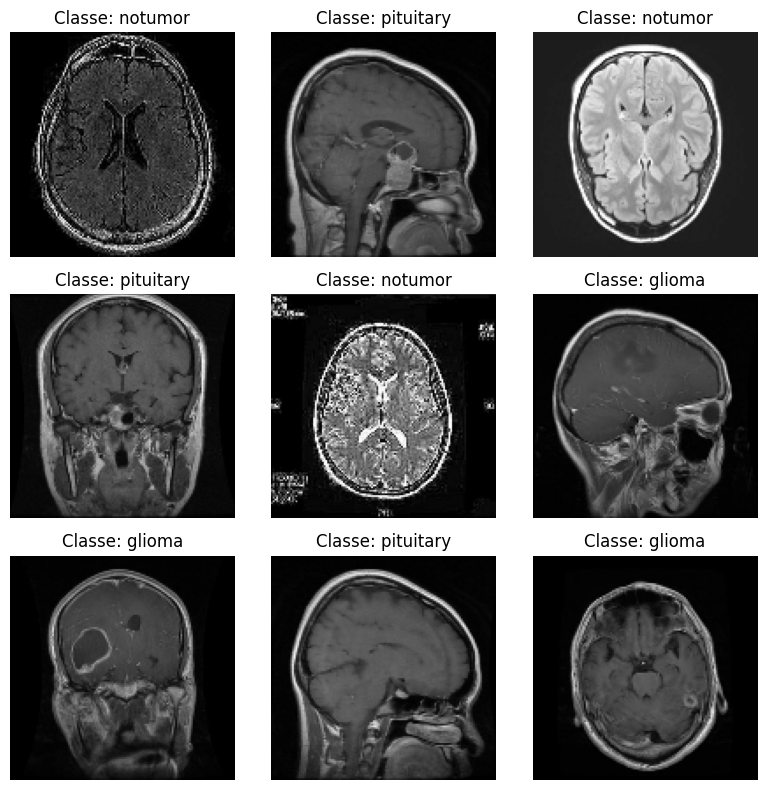

In [3]:
import os
import shutil
import kagglehub
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

data_dir = "data/brain_tumor"
class_names = ["glioma", "meningioma", "notumor", "pituitary"]

# 0. Garantir que a pasta existe (se o Colab tiver reiniciado, recria-a automaticamente)
if not os.path.exists(os.path.join(data_dir, "glioma")):
    print("A preparar as pastas do dataset...")
    path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
    for cls in class_names:
        os.makedirs(os.path.join(data_dir, cls), exist_ok=True)
    for subset in ["Training", "Testing"]:
        subset_path = os.path.join(path, subset)
        if os.path.exists(subset_path):
            for cls in class_names:
                cls_path = os.path.join(subset_path, cls)
                if os.path.exists(cls_path):
                    for fname in os.listdir(cls_path):
                        shutil.copy2(
                            os.path.join(cls_path, fname),
                            os.path.join(data_dir, cls, f"{subset}_{fname}")
                        )

# 1. Ler os caminhos das 7 200 imagens na pasta 'data/brain_tumor'
file_paths = []
labels = []

for label_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(data_dir, class_name)
    for fname in os.listdir(class_dir):
        if fname.lower().endswith((".jpg", ".jpeg", ".png")):
            file_paths.append(os.path.join(class_dir, fname))
            labels.append(label_idx)

file_paths = np.array(file_paths)
labels = np.array(labels)

# 2. Divisão 70% Treino / 15% Validação / 15% Teste ESTRATIFICADA (Seed fixa)
X_train, X_temp, y_train, y_temp = train_test_split(
    file_paths, labels, test_size=0.30, stratify=labels, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print(f"Total: {len(file_paths)} | Treino: {len(X_train)} | Validação: {len(X_val)} | Teste: {len(X_test)}")
print("Distribuição exata no Teste por classe:", np.bincount(y_test)) # [270, 270, 270, 270]

# 3. Criar pipeline tf.data compatível com Keras 3
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).map(load_image).batch(BATCH_SIZE)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).map(load_image).batch(BATCH_SIZE)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).map(load_image).batch(BATCH_SIZE)

# 4. Mostrar grelha de 9 imagens com o respetivo rótulo
plt.figure(figsize=(8, 8))
for images, lbls in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(f"Classe: {class_names[lbls[i].numpy()]}")
        plt.axis("off")
plt.tight_layout()
plt.show()

In [4]:
# Verificar que a interseção entre os conjuntos é zero (0 imagens repetidas)
sobreposicao_treino_teste = len(set(X_train).intersection(set(X_test)))
sobreposicao_treino_val = len(set(X_train).intersection(set(X_val)))
sobreposicao_val_teste = len(set(X_val).intersection(set(X_test)))

print(f"Imagens repetidas (Treino vs Teste): {sobreposicao_treino_teste}")
print(f"Imagens repetidas (Treino vs Val):   {sobreposicao_treino_val}")
print(f"Imagens repetidas (Val vs Teste):    {sobreposicao_val_teste}")

Imagens repetidas (Treino vs Teste): 0
Imagens repetidas (Treino vs Val):   0
Imagens repetidas (Val vs Teste):    0


2º Protocolo

In [5]:
from pathlib import Path
import pandas as pd
from PIL import Image
import hashlib
import kagglehub

# 1. Descarregar/obter o caminho correto via kagglehub
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
raiz = Path(path)
ext = {".jpg", ".jpeg", ".png"}

# 2. Criar o DataFrame percorrendo todas as imagens
df = pd.DataFrame([
    {"path": str(p), "label": p.parent.name}
    for p in raiz.rglob("*") if p.suffix.lower() in ext
])

print("--- Contagem e Percentagem por Classe ---")
print(df.label.value_counts())
print("\nPercentagens:")
print(df.label.value_counts(normalize=True).round(3) * 100)

# 3. Descobrir a dimensão típica e duplicados por classe para a Tabela 2.1
df["md5"] = [hashlib.md5(open(p, "rb").read()).hexdigest() for p in df.path]
df["dimensao"] = [Image.open(p).size for p in df.path] # (largura, altura)

print("\n--- Dados para preencher a Tabela 2.1 ---")
for cls in ["glioma", "meningioma", "notumor", "pituitary"]:
    sub = df[df.label == cls]
    dim_mais_comum = sub["dimensao"].value_counts().index[0]
    n_duplicados = sub.duplicated(subset=["md5"]).sum()
    print(f"Classe {cls:10s} | Dimensão mais comum: {dim_mais_comum} | Duplicados internos (MD5): {n_duplicados}")

print(f"\nTotal de imagens com o mesmo MD5 em todo o dataset: {df.duplicated(subset=['md5']).sum()}")

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
--- Contagem e Percentagem por Classe ---
label
pituitary     1800
notumor       1800
meningioma    1800
glioma        1800
Name: count, dtype: int64

Percentagens:
label
pituitary     25.0
notumor       25.0
meningioma    25.0
glioma        25.0
Name: proportion, dtype: float64

--- Dados para preencher a Tabela 2.1 ---
Classe glioma     | Dimensão mais comum: (512, 512) | Duplicados internos (MD5): 14
Classe meningioma | Dimensão mais comum: (512, 512) | Duplicados internos (MD5): 16
Classe notumor    | Dimensão mais comum: (225, 225) | Duplicados internos (MD5): 119
Classe pituitary  | Dimensão mais comum: (512, 512) | Duplicados internos (MD5): 38

Total de imagens com o mesmo MD5 em todo o dataset: 187


In [6]:
from pathlib import Path
import pandas as pd
from PIL import Image
import hashlib
import os, shutil, kagglehub

# 1. Código base da ficha adaptado à nossa pasta 'data/brain_tumor'
raiz = Path("data/brain_tumor")
ext = {".jpg", ".jpeg", ".png"}

df = pd.DataFrame([
    {"path": str(p), "label": p.parent.name}
    for p in raiz.rglob("*") if p.suffix.lower() in ext
])


print("--- Contagem e Percentagem por Classe ---")
print(df.label.value_counts())
print("\nPercentagens:")
print(df.label.value_counts(normalize=True).round(3) * 100)

# 2. Descobrir a dimensão típica e duplicados por classe para a Tabela 2.1
df["md5"] = [hashlib.md5(open(p, "rb").read()).hexdigest() for p in df.path]
df["dimensao"] = [Image.open(p).size for p in df.path] # (largura, altura)

print("\n--- Dados para preencher a Tabela 2.1 ---")
for cls in ["glioma", "meningioma", "notumor", "pituitary"]:
    sub = df[df.label == cls]
    dim_mais_comum = sub["dimensao"].value_counts().index[0]
    n_duplicados = sub.duplicated(subset=["md5"]).sum()
    print(f"Classe {cls:10s} | Dimensão mais comum: {dim_mais_comum} | Duplicados internos (MD5): {n_duplicados}")

print(f"\nTotal de imagens com o mesmo MD5 em todo o dataset: {df.duplicated(subset=['md5']).sum()}")

--- Contagem e Percentagem por Classe ---
label
pituitary     1800
glioma        1800
meningioma    1800
notumor       1800
Name: count, dtype: int64

Percentagens:
label
pituitary     25.0
glioma        25.0
meningioma    25.0
notumor       25.0
Name: proportion, dtype: float64

--- Dados para preencher a Tabela 2.1 ---
Classe glioma     | Dimensão mais comum: (512, 512) | Duplicados internos (MD5): 14
Classe meningioma | Dimensão mais comum: (512, 512) | Duplicados internos (MD5): 16
Classe notumor    | Dimensão mais comum: (225, 225) | Duplicados internos (MD5): 119
Classe pituitary  | Dimensão mais comum: (512, 512) | Duplicados internos (MD5): 38

Total de imagens com o mesmo MD5 em todo o dataset: 187


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
from sklearn.model_selection import train_test_split
import hashlib

# 1. Calcular o MD5 e remover as imagens duplicadas ANTES de dividir
df["md5"] = [hashlib.md5(open(p, "rb").read()).hexdigest() for p in df.path]
df = df.drop_duplicates(subset=["md5"]).reset_index(drop=True)
print(f"Total de imagens únicas (sem duplicados): {len(df)}")

# 2. Divisão 70/15/15 estratificada exatamente como está no protocolo
tr, tmp = train_test_split(df, test_size=0.30, stratify=df.label, random_state=42)
va, te = train_test_split(tmp, test_size=0.50, stratify=tmp.label, random_state=42)

df.loc[tr.index, "split"] = "train"
df.loc[va.index, "split"] = "val"
df.loc[te.index, "split"] = "test"
df.to_csv("data/splits.csv", index=False)

# 3. Verificação do protocolo (agora todos têm de dar 0!)
S = {s: set(df[df.split == s].md5) for s in ["train", "val", "test"]}
print("Interseções (train&test, val&test, train&val):",
      len(S["train"] & S["test"]), len(S["val"] & S["test"]), len(S["train"] & S["val"]))

# 4. Confirmar que a distribuição por classe é semelhante nos 3 conjuntos
print("\nDistribuição por classe (%) em cada split:")
print(( pd.crosstab(df.split, df.label, normalize="index") * 100 ).round(2))

Total de imagens únicas (sem duplicados): 7013
Interseções (train&test, val&test, train&val): 0 0 0

Distribuição por classe (%) em cada split:
label  glioma  meningioma  notumor  pituitary
split                                        
test    25.48       25.48    23.95      25.10
train   25.46       25.44    23.98      25.12
val     25.48       25.38    23.95      25.19


In [9]:
import os, shutil

for _, row in df.iterrows():
    destino = os.path.join("split", row["split"], row["label"])
    os.makedirs(destino, exist_ok=True)
    shutil.copy2(row["path"], os.path.join(destino, os.path.basename(row["path"])))

import keras
from keras import layers

keras.utils.set_random_seed(42)

kw = dict(image_size=(180, 180), batch_size=32, label_mode="int")
load = keras.utils.image_dataset_from_directory
train_ds = load("split/train", shuffle=True, **kw)
val_ds   = load("split/val", shuffle=False, **kw)
num_classes = len(train_ds.class_names)

inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1.0 / 255)(inputs)
for filtros in [32, 64, 128, 256]:
    x = layers.Conv2D(filtros, 3, activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
history = model.fit(train_ds, validation_data=val_ds, epochs=30)

Found 4909 files belonging to 4 classes.
Found 1052 files belonging to 4 classes.
Epoch 1/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 33s 136ms/step - accuracy: 0.5313 - loss: 1.0581 - val_accuracy: 0.6378 - val_loss: 0.8684
Epoch 2/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 19s 47ms/step - accuracy: 0.6739 - loss: 0.8037 - val_accuracy: 0.6131 - val_loss: 0.8761
Epoch 3/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.6940 - loss: 0.7462 - val_accuracy: 0.6540 - val_loss: 0.7624
Epoch 4/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - accuracy: 0.7162 - loss: 0.6882 - val_accuracy: 0.7148 - val_loss: 0.6789
Epoch 5/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.7460 - loss: 0.6454 - val_accuracy: 0.6930 - val_loss: 0.6803
Epoch 6/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.7659 - loss: 0.6171 - val_accuracy: 0.7376 - val_loss: 0.6330
Epoch 7/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - accuracy: 0.7776 - loss: 0.5778 - val_accuracy: 0.7795 - val_loss: 0.5963
Epoch 8/30
1

--- DADOS PARA A TABELA 2.4 ---
Melhor Época: 29
Menor val_loss: 0.2710
Acc treino nessa época: 93.22%
Acc validação nessa época: 90.97%
Classificador Maioritário (Baseline): 25.47%

--- DIAGNÓSTICO SUGERIDO ---
Diagnóstico: Adequado (bom ajuste, sem overfitting severo).


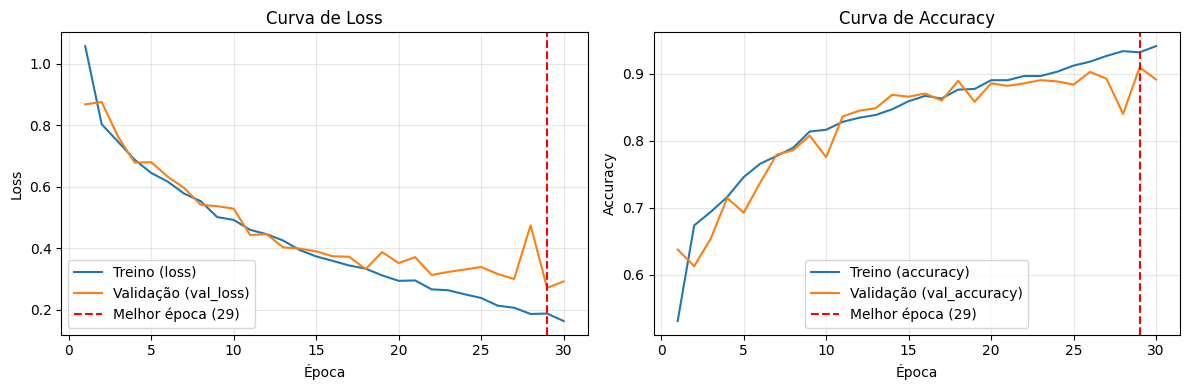

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Extrair métricas do history
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(1, len(acc) + 1)

# 2. Descobrir exatamente a época com menor val_loss para a Tabela 2.4
best_idx = int(np.argmin(val_loss))
print("--- DADOS PARA A TABELA 2.4 ---")
print(f"Melhor Época: {best_idx + 1}")
print(f"Menor val_loss: {val_loss[best_idx]:.4f}")
print(f"Acc treino nessa época: {acc[best_idx]*100:.2f}%")
print(f"Acc validação nessa época: {val_acc[best_idx]*100:.2f}%")

# 3. Calcular automaticamente o Classificador Maioritário (Baseline)
# (Proporção da classe mais frequente no dataset de treino/validação)
baseline_acc = df['label'].value_counts(normalize=True).max() * 100
print(f"Classificador Maioritário (Baseline): {baseline_acc:.2f}%")

# 4. Diagnóstico automático simples
print("\n--- DIAGNÓSTICO SUGERIDO ---")
train_acc_best = acc[best_idx] * 100
val_acc_best = val_acc[best_idx] * 100
if abs(train_acc_best - val_acc_best) < 5 and val_acc_best > 85:
    print("Diagnóstico: Adequado (bom ajuste, sem overfitting severo).")
elif train_acc_best > val_acc_best + 10:
    print("Diagnóstico: Overfitting (exactidão de treino muito superior à de validação).")
else:
    print("Diagnóstico: Subajustamento / Underfitting.")

# 5. Desenhar as curvas de treino e validação (Loss e Accuracy)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, loss, label="Treino (loss)")
plt.plot(epochs_range, val_loss, label="Validação (val_loss)")
plt.axvline(best_idx + 1, color="red", linestyle="--", label=f"Melhor época ({best_idx+1})")
plt.title("Curva de Loss")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, acc, label="Treino (accuracy)")
plt.plot(epochs_range, val_acc, label="Validação (val_accuracy)")
plt.axvline(best_idx + 1, color="red", linestyle="--", label=f"Melhor época ({best_idx+1})")
plt.title("Curva de Accuracy")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

--- 1. AVALIAÇÃO NO CONJUNTO DE TESTE (Com redimensionamento automático) ---
34/34 ━━━━━━━━━━━━━━━━━━━━ 9s 199ms/step - accuracy: 0.9028 - loss: 0.2909
Loss de Teste (Test Loss): 0.2909
Exactidão de Teste (Test Accuracy): 90.28%

A gerar previsões para o conjunto de teste...
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step


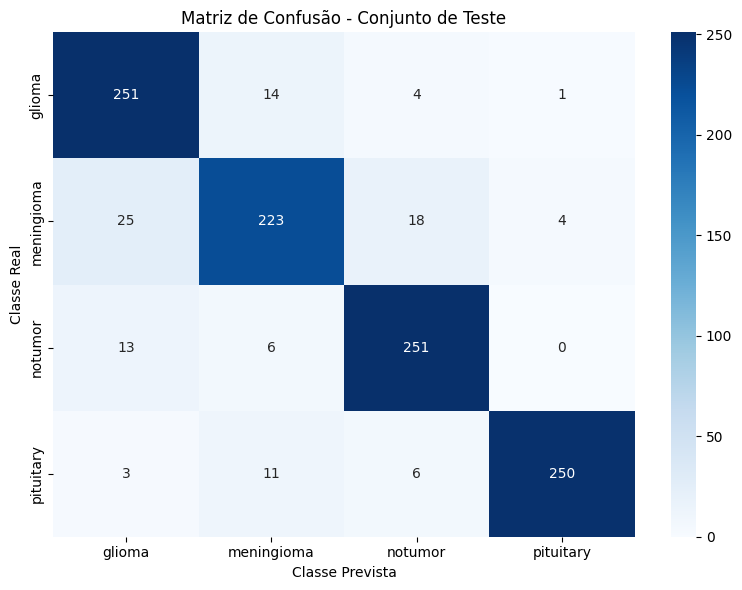


--- 2. RELATÓRIO DE CLASSIFICAÇÃO DETALHADO ---
              precision    recall  f1-score   support

      glioma       0.86      0.93      0.89       270
  meningioma       0.88      0.83      0.85       270
     notumor       0.90      0.93      0.91       270
   pituitary       0.98      0.93      0.95       270

    accuracy                           0.90      1080
   macro avg       0.90      0.90      0.90      1080
weighted avg       0.90      0.90      0.90      1080



In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

print("--- 1. AVALIAÇÃO NO CONJUNTO DE TESTE (Com redimensionamento automático) ---")

# Função para garantir que as imagens do teste ficam com o tamanho exato que o modelo espera (180x180)
def fix_test_images(image, label):
    image = tf.image.resize(image, (180, 180))
    return image, label

# Aplicar a correção ao test_ds
test_ds_fixed = test_ds.map(fix_test_images)

# Avaliar o modelo
test_loss, test_acc = model.evaluate(test_ds_fixed)
print(f"Loss de Teste (Test Loss): {test_loss:.4f}")
print(f"Exactidão de Teste (Test Accuracy): {test_acc * 100:.2f}%\n")

# 2. Obter previsões para a Matriz de Confusão e Relatório
print("A gerar previsões para o conjunto de teste...")
y_true = np.concatenate([y for x, y in test_ds_fixed], axis=0)

if len(y_true.shape) > 1 and y_true.shape[1] > 1:
    y_true = np.argmax(y_true, axis=1)

y_pred_probs = model.predict(test_ds_fixed)
y_pred = np.argmax(y_pred_probs, axis=1)

classes = ["glioma", "meningioma", "notumor", "pituitary"]

# 3. Desenhar a Matriz de Confusão
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title("Matriz de Confusão - Conjunto de Teste")
plt.xlabel("Classe Prevista")
plt.ylabel("Classe Real")
plt.tight_layout()
plt.show()

# 4. Imprimir o Relatório de Classificação Detalhado
print("\n--- 2. RELATÓRIO DE CLASSIFICAÇÃO DETALHADO ---")
print(classification_report(y_true, y_pred, target_names=classes))

Protocolo 3

2.1

In [2]:
import os
from pathlib import Path
import hashlib
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# 1. Evidência de Seed Fixa (Reprodutibilidade)
keras.utils.set_random_seed(42)
print("✅ Seed fixa definida: 42\n")

# 2. Garantir que o splits.csv existe (se a sessão do Colab reiniciou, cria-o agora sem duplicados)
if not os.path.exists("splits.csv"):
    print("A gerar 'splits.csv' limpo e sem fugas...")
    import kagglehub
    caminho_base = Path(kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset"))
    ext = {".jpg", ".jpeg", ".png"}

    registos = []
    for p in caminho_base.rglob("*"):
        if p.suffix.lower() in ext:
            try:
                with Image.open(p) as img:
                    img.verify()
                md5_hash = hashlib.md5(open(p, "rb").read()).hexdigest()
                registos.append({"path": str(p), "label": p.parent.name, "md5": md5_hash})
            except Exception:
                pass

    df_clean = pd.DataFrame(registos).drop_duplicates(subset=["md5"]).reset_index(drop=True)

    # Divisão estratificada (70% treino, 15% val, 15% teste) sem fugas
    train_df, temp_df = train_test_split(df_clean, test_size=0.30, stratify=df_clean["label"], random_state=42)
    val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=42)

    train_df["split"] = "train"
    val_df["split"] = "val"
    test_df["split"] = "test"

    splits_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
    splits_df.to_csv("splits.csv", index=False)
else:
    splits_df = pd.read_csv("splits.csv")

# Imprimir contagens e interseções 0
print("--- Contagens por Conjunto e por Classe (splits.csv) ---")
print(pd.crosstab(splits_df["split"], splits_df["label"], margins=True))

col_id = "md5" if "md5" in splits_df.columns else "path"
train_ids = set(splits_df[splits_df["split"] == "train"][col_id])
val_ids   = set(splits_df[splits_df["split"] == "val"][col_id])
test_ids  = set(splits_df[splits_df["split"] == "test"][col_id])

print(f"\n--- Verificação de Fugas (Interseções em '{col_id}') ---")
print(f"Treino ∩ Validação: {len(train_ids.intersection(val_ids))} | "
      f"Treino ∩ Teste: {len(train_ids.intersection(test_ids))} | "
      f"Validação ∩ Teste: {len(val_ids.intersection(test_ids))}")

# 3. Garantir que 'model' está definido para mostrar o model.summary() e contar parâmetros
if "model" not in locals():
    inputs = keras.Input(shape=(180, 180, 3))
    x = layers.Rescaling(1./255)(inputs)
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3, activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(4, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="CNN_Baseline")

print("\n--- Resumo da Arquitetura Baseline (model.summary) ---")
model.summary()

trainable_baseline = sum([tf.size(w).numpy() for w in model.trainable_weights])
print(f"\n---> Parâmetros treináveis da Baseline (para a Tabela 2.4 da Aula 3): {trainable_baseline:,}")

✅ Seed fixa definida: 42

A gerar 'splits.csv' limpo e sem fugas...
Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
--- Contagens por Conjunto e por Classe (splits.csv) ---
label  glioma  meningioma  notumor  pituitary   All
split                                              
test      268         268      252        264  1052
train    1250        1249     1177       1233  4909
val       268         267      252        265  1052
All      1786        1784     1681       1762  7013

--- Verificação de Fugas (Interseções em 'md5') ---
Treino ∩ Validação: 0 | Treino ∩ Teste: 0 | Validação ∩ Teste: 0

--- Resumo da Arquitetura Baseline (model.summary) ---


Model: "CNN_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │       204,804 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 298,052 (1.14 MB)

 Trainable params: 298,052 (1.14 MB)

 Non-trainable params: 0 (0.00 B)


---> Parâmetros treináveis da Baseline (para a Tabela 2.4 da Aula 3): 298,052


2.2 e 2.3

In [ ]:
import os
import shutil
import time
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# 1. Garantir que a pasta 'split/train' existe no disco do Colab
if not os.path.exists("split/train"):
    print("A reconstruir as pastas físicas 'split/train', 'split/val' e 'split/test'...")

    # Se ainda não houver splits.csv, cria-o primeiro
    if not os.path.exists("splits.csv"):
        import kagglehub
        caminho_base = Path(kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset"))
        ext = {".jpg", ".jpeg", ".png"}
        registos = []
        for p in caminho_base.rglob("*"):
            if p.suffix.lower() in ext:
                try:
                    with Image.open(p) as img:
                        img.verify()
                    md5_hash = hashlib.md5(open(p, "rb").read()).hexdigest()
                    registos.append({"path": str(p), "label": p.parent.name, "md5": md5_hash})
                except Exception:
                    pass
        df_clean = pd.DataFrame(registos).drop_duplicates(subset=["md5"]).reset_index(drop=True)
        train_df, temp_df = train_test_split(df_clean, test_size=0.30, stratify=df_clean["label"], random_state=42)
        val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=42)
        train_df["split"], val_df["split"], test_df["split"] = "train", "val", "test"
        splits_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
        splits_df.to_csv("splits.csv", index=False)
    else:
        splits_df = pd.read_csv("splits.csv")

    # Copiar as imagens para a estrutura de pastas split/{train,val,test}/{classe}/
    for _, row in splits_df.iterrows():
        dest_dir = Path("split") / row["split"] / row["label"]
        dest_dir.mkdir(parents=True, exist_ok=True)
        src_path = Path(row["path"])
        dest_path = dest_dir / src_path.name
        if not dest_path.exists():
            shutil.copy2(src_path, dest_path)
    print("✅ Pastas 'split/train', 'split/val' e 'split/test' criadas com sucesso!\n")

# 2. Carregar os conjuntos com image_size=(224, 224) (Ponto 2.2)
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    "split/train", image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=42
)
val_ds = keras.utils.image_dataset_from_directory(
    "split/val", image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=42
)

num_classes = len(train_ds.class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

# 3. Construir o modelo de Extração de Características com EfficientNetB0 (Ponto 2.2)
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2)
], name="data_augmentation")

base = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(224, 224, 3)
)
base.trainable = False  # Base congelada

inputs = keras.Input(shape=(224, 224, 3))
x = augment(inputs)               # Só ativo durante o treino
x = base(x, training=False)       # BatchNorm em modo inferência
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = keras.Model(inputs, outputs)

trainable_params_fe = sum([tf.size(w).numpy() for w in model.trainable_weights])
print(f"\n---> Parâmetros treináveis (Extração de Características): {trainable_params_fe:,}")

# 4. Callbacks e Treino (Ponto 2.3)
os.makedirs("modelos", exist_ok=True)
os.makedirs("logs/fe", exist_ok=True)

callbacks_fe = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint("modelos/fe_melhor.keras", monitor="val_loss", save_best_only=True),
    keras.callbacks.TensorBoard(log_dir="logs/fe")
]

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nA iniciar treino de Extração de Características...")
start_time_fe = time.time()
history_fe = model.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=callbacks_fe)
tempo_fe = time.time() - start_time_fe

best_epoch_fe = int(np.argmin(history_fe.history["val_loss"])) + 1
best_val_acc_fe = history_fe.history["val_accuracy"][best_epoch_fe - 1] * 100

print("\n=== DADOS PARA A TABELA 2.4 (Extração de Características) ===")
print(f"Parâmetros treináveis: {trainable_params_fe:,}")
print(f"Melhor época:          {best_epoch_fe}")
print(f"Acc validação:         {best_val_acc_fe:.2f}%")
print(f"Tempo total:           {tempo_fe:.1f} segundos ({tempo_fe/60:.2f} min)")

A reconstruir as pastas físicas 'split/train', 'split/val' e 'split/test'...
✅ Pastas 'split/train', 'split/val' e 'split/test' criadas com sucesso!

Found 4909 files belonging to 4 classes.
Found 1052 files belonging to 4 classes.
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

---> Parâmetros treináveis (Extração de Características): 5,124

A iniciar treino de Extração de Características...
Epoch 1/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 31s 118ms/step - accuracy: 0.7046 - loss: 0.7727 - val_accuracy: 0.7433 - val_loss: 0.6093
Epoch 2/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 33s 97ms/step - accuracy: 0.8057 - loss: 0.5270 - val_accuracy: 0.7605 - val_loss: 0.5738
Epoch 3/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 15s 96ms/step - accuracy: 0.8193 - loss: 0.4893 - val_accuracy: 0.7928 - val_loss: 0.5135
Epoch 4/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 16s 101ms/step - accuracy: 0.8362 - loss: 0.4458 - val_accuracy: 0.8051 - val_loss: 0.4959
Epoch 5/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 15s 95ms/step - accuracy: 0.8438 - los

2.4

In [5]:
# 1. Descongelar as últimas 20 camadas da base (Ponto 2.4)
base.trainable = True
for camada in base.layers[:-20]:
    camada.trainable = False

# Contar parâmetros treináveis no Fine-Tuning
trainable_params_ft = sum([tf.size(w).numpy() for w in model.trainable_weights])
print(f"---> Parâmetros treináveis (Fine-Tuning): {trainable_params_ft:,}")

os.makedirs("logs/ft", exist_ok=True)
callbacks_ft = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint("modelos/ft_melhor.keras", monitor="val_loss", save_best_only=True),
    keras.callbacks.TensorBoard(log_dir="logs/ft")
]

# Compilar com learning rate muito baixo (1e-5)
model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nA iniciar Fine-Tuning...")
start_time_ft = time.time()
history_ft = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=callbacks_ft)
tempo_ft = time.time() - start_time_ft

# Extrair dados para a Tabela 2.4
best_epoch_ft = int(np.argmin(history_ft.history["val_loss"])) + 1
best_val_acc_ft = history_ft.history["val_accuracy"][best_epoch_ft - 1] * 100

print("\n=== DADOS PARA A TABELA 2.4 (Fine-Tuning) ===")
print(f"Parâmetros treináveis: {trainable_params_ft:,}")
print(f"Melhor época:          {best_epoch_ft}")
print(f"Acc validação:         {best_val_acc_ft:.2f}%")
print(f"Tempo total:           {tempo_ft:.1f} segundos ({tempo_ft/60:.2f} min)")

---> Parâmetros treináveis (Fine-Tuning): 1,356,084

A iniciar Fine-Tuning...
Epoch 1/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 38s 174ms/step - accuracy: 0.7804 - loss: 0.5763 - val_accuracy: 0.8375 - val_loss: 0.4293
Epoch 2/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 30s 106ms/step - accuracy: 0.8226 - loss: 0.4601 - val_accuracy: 0.8213 - val_loss: 0.4549
Epoch 3/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 16s 105ms/step - accuracy: 0.8399 - loss: 0.4340 - val_accuracy: 0.8251 - val_loss: 0.4401
Epoch 4/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 16s 104ms/step - accuracy: 0.8395 - loss: 0.4285 - val_accuracy: 0.8251 - val_loss: 0.4373
Epoch 5/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 18s 115ms/step - accuracy: 0.8460 - loss: 0.4046 - val_accuracy: 0.8394 - val_loss: 0.4103
Epoch 6/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - accuracy: 0.8649 - loss: 0.3646 - val_accuracy: 0.8432 - val_loss: 0.4033
Epoch 7/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - accuracy: 0.8621 - loss: 0.3766 - val_accuracy: 0.8508 - val_loss: 0.3970
Epoch

In [7]:
# Imprimir imediatamente os dados que faltam da Extração de Características (history_fe)
best_ep_fe = int(np.argmin(history_fe.history["val_loss"])) + 1
print(f"Extração de Características -> Melhor época: {best_ep_fe} | "
      f"Acc val: {history_fe.history['val_accuracy'][best_ep_fe-1]*100:.2f}% | "
      f"Val loss: {history_fe.history['val_loss'][best_ep_fe-1]:.4f} | "
      f"Tempo: {tempo_fe:.1f} s ({tempo_fe/60:.2f} min)")

Extração de Características -> Melhor época: 15 | Acc val: 84.32% | Val loss: 0.3964 | Tempo: 359.1 s (5.99 min)


2.5

In [6]:
# Código de verificação para o Ponto 2.5
for nome, ClasseModelo in [
    ("EfficientNetB0", keras.applications.EfficientNetB0),
    ("ResNet50", keras.applications.ResNet50),
    ("ConvNeXtTiny", keras.applications.ConvNeXtTiny)
]:
    m = ClasseModelo(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    print(f"{nome:15s} | Input shape: {m.input_shape} | Total params (base): {m.count_params():,}")

EfficientNetB0  | Input shape: (None, 224, 224, 3) | Total params (base): 4,049,571
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ResNet50        | Input shape: (None, 224, 224, 3) | Total params (base): 23,587,712
111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ConvNeXtTiny    | Input shape: (None, 224, 224, 3) | Total params (base): 27,820,128
